# 01 · Exploratory Data Analysis — NASA C-MAPSS

**AeroRUL** · Remaining Useful Life prediction for turbofan engines

This notebook builds the domain understanding that drives every modelling decision of the project:

1. What do the four sub-datasets look like and how do they differ?
2. How long do engines live, and how are the test trajectories truncated?
3. Which of the 21 sensors carry degradation signal?
4. How strongly do operating regimes mask degradation (FD002 / FD004)?
5. Why clip the RUL target at 125 cycles?

> **Business framing.** An unplanned engine removal (AOG event, secondary damage, schedule disruption) costs several times a planned shop visit. Every cycle of warning we can reliably give converts an unplanned event into a planned one. The data analysis below is therefore oriented toward one question: *how early, and how reliably, does degradation become visible in the sensors?*

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import load_config
from src.utils import visualization as viz
from src.data.load_data import load_dataset, DATASET_INFO, SENSOR_DESCRIPTIONS, SENSORS
from src.data.preprocess import add_train_rul
from src.features.engineering import OperatingConditionNormalizer

cfg = load_config(ROOT / "config.yaml")
viz.set_style()
FIG = ROOT / cfg["paths"]["figures_dir"]
data = {name: load_dataset(name, ROOT / cfg["paths"]["raw_dir"]) for name in DATASET_INFO}
train = {n: add_train_rul(d.train, cfg["target"]["max_rul"]) for n, d in data.items()}

00:15:41 | INFO    | src.data.load_data | Loaded FD001: 100 train engines (20631 rows), 100 test engines (13096 rows)


00:15:42 | INFO    | src.data.load_data | Loaded FD002: 260 train engines (53759 rows), 259 test engines (33991 rows)


00:15:42 | INFO    | src.data.load_data | Loaded FD003: 100 train engines (24720 rows), 100 test engines (16596 rows)


00:15:43 | INFO    | src.data.load_data | Loaded FD004: 249 train engines (61249 rows), 248 test engines (41214 rows)


## 1. Dataset overview

The simulation (Saxena et al., 2008) generates multivariate time series of 21 sensors + 3 operating settings. Each training engine starts with an unknown level of manufacturing wear and runs until a fault threshold is reached. Test engines are cut at a random point before failure; the goal is to predict the remaining cycles at the cut.

In [2]:
rows = []
for name, ds in data.items():
    life = ds.train.groupby("unit")["cycle"].max()
    test_len = ds.test.groupby("unit")["cycle"].max()
    rows.append({"dataset": name, **DATASET_INFO[name],
                 "train engines": ds.n_train_engines, "test engines": ds.n_test_engines,
                 "train rows": len(ds.train), "life min": life.min(), "life median": int(life.median()),
                 "life max": life.max(), "test record median": int(test_len.median()),
                 "test RUL median": int(ds.test_rul.median())})
overview = pd.DataFrame(rows).set_index("dataset")
overview

,conditions,fault_modes,faults,train engines,test engines,train rows,life min,life median,life max,test record median,test RUL median
dataset,,,,,,,,,,,
FD001,1,1,HPC degradation,100,100,20631,128,199,362,133,86
FD002,6,1,HPC degradation,260,259,53759,128,199,378,132,80
FD003,1,2,HPC + Fan degradation,100,100,24720,145,220,525,148,77
FD004,6,2,HPC + Fan degradation,249,248,61249,128,234,543,153,88


**Observations**
* FD002 and FD004 are 2.5× larger and contain **six operating regimes**; FD003 and FD004 combine **two fault modes** (HPC and fan degradation). FD004 is the hardest scenario: both difficulties at once.
* Lifetimes vary by a factor of ~2–3 within each fleet: a fixed-interval maintenance policy must be conservative to protect the short-lived engines, which wastes the life of the long-lived ones. That spread is the economic opportunity of predictive maintenance.

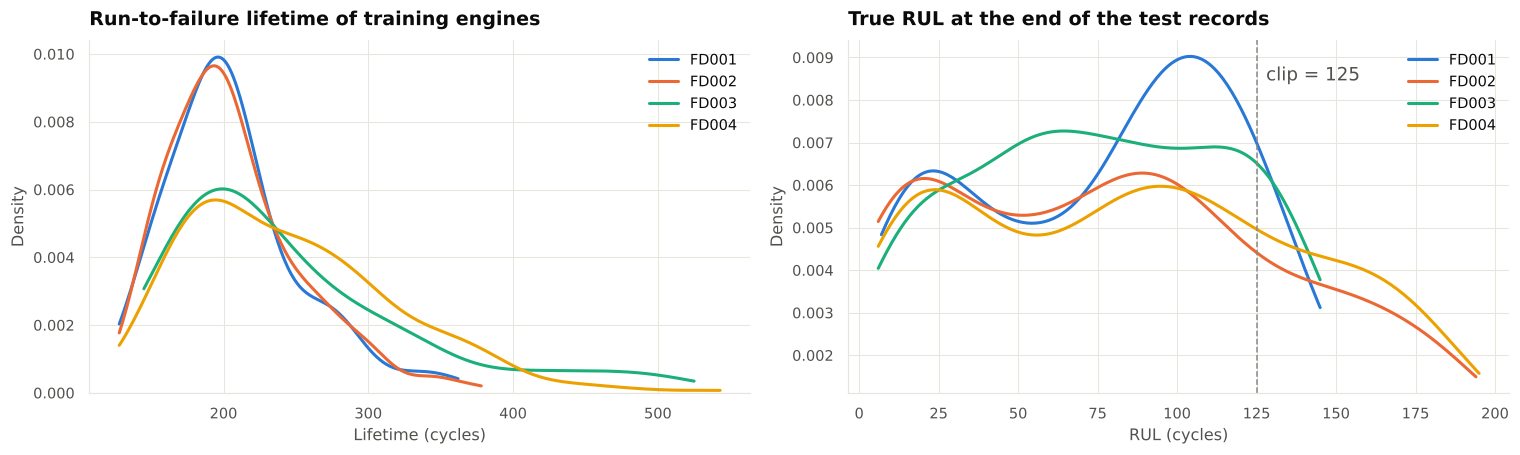

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for i, (name, ds) in enumerate(data.items()):
    life = ds.train.groupby("unit")["cycle"].max()
    sns.kdeplot(life, ax=axes[0], color=viz.PALETTE[i], label=name, lw=2, cut=0)
    sns.kdeplot(ds.test_rul, ax=axes[1], color=viz.PALETTE[i], label=name, lw=2, cut=0)
axes[0].set(title="Run-to-failure lifetime of training engines", xlabel="Lifetime (cycles)")
axes[1].set(title="True RUL at the end of the test records", xlabel="RUL (cycles)")
axes[1].axvline(cfg["target"]["max_rul"], color=viz.INK_3, ls="--", lw=1)
axes[1].text(cfg["target"]["max_rul"] + 3, axes[1].get_ylim()[1] * 0.9, "clip = 125", color=viz.INK_2)
for ax in axes: ax.legend()
fig.tight_layout(); viz.save_figure(fig, "eda_lifetimes", FIG); plt.show()

The test RUL distribution is broad (from a few cycles to ~150+). Validation must mimic this: in `src.data.preprocess.sample_truncation_points`, held-out training engines are evaluated at **random truncation points**, not only at failure.

## 2. Operating regimes

The three operating settings (altitude, Mach number, throttle resolver angle) form tight clusters in FD002/FD004.

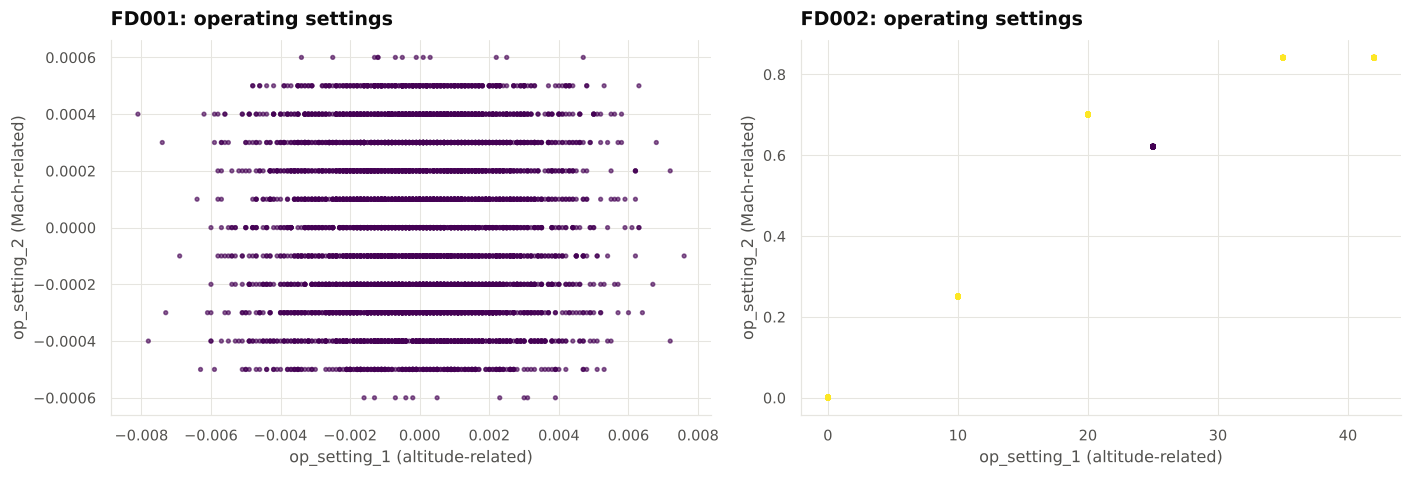

Rows per discovered regime (FD002): [13458  8044  8122  8002  8096  8037]


In [4]:
ops = cfg["data"]["operating_settings"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, name in zip(axes, ["FD001", "FD002"]):
    d = data[name].train.sample(6000, random_state=0)
    ax.scatter(d[ops[0]], d[ops[1]], c=d[ops[2]], cmap="viridis", s=6, alpha=0.6)
    ax.set(title=f"{name}: operating settings", xlabel="op_setting_1 (altitude-related)",
           ylabel="op_setting_2 (Mach-related)")
fig.tight_layout(); viz.save_figure(fig, "eda_operating_settings", FIG); plt.show()

norm = OperatingConditionNormalizer(cfg["data"]["sensors"], n_conditions=6, op_cols=ops).fit(data["FD002"].train)
labels = norm._assign(data["FD002"].train)
print("Rows per discovered regime (FD002):", np.bincount(labels))

K-Means finds six well-separated clusters, matching the six documented regimes (one regime, sea-level take-off, is more frequent than the others). Now the key question: **how much of the sensor variance is regime vs. degradation?**

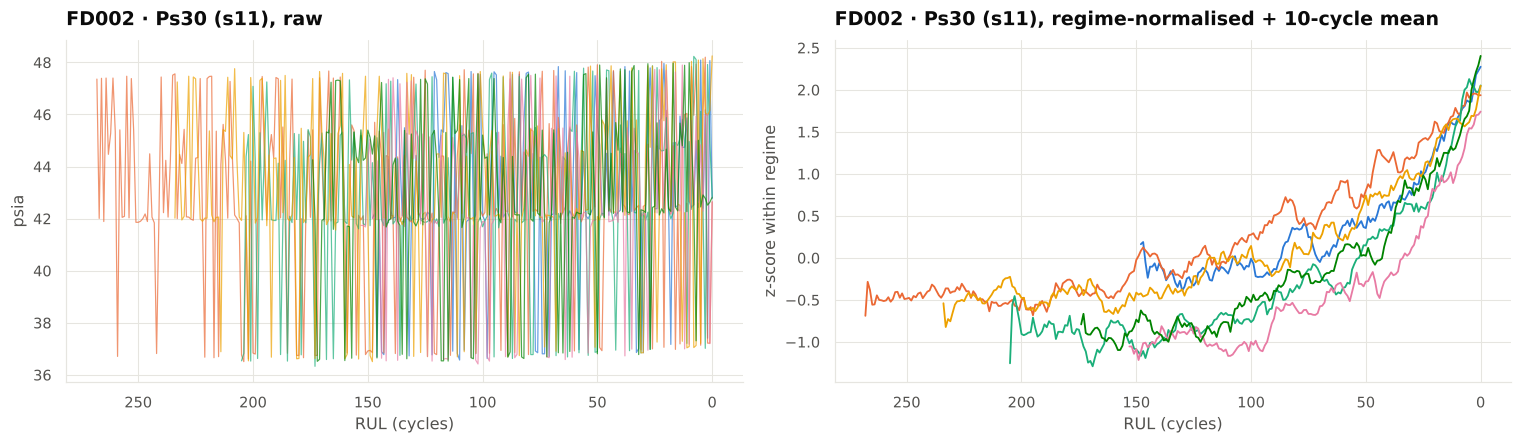

sensor,s2,s3,s4,s7,s8,s9,s11,s12,s13,s14,s15,s17,s20,s21
variance explained by regime,1.0,0.997,0.996,1.0,1.0,0.997,0.995,1.0,1.0,0.967,0.997,0.997,1.0,1.0


In [5]:
d = train["FD002"]
normalized = norm.transform(d)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for unit in d["unit"].unique()[:6]:
    m = d["unit"] == unit
    axes[0].plot(d.loc[m, "rul_true"], d.loc[m, "s11"], lw=0.8, alpha=0.7)
    axes[1].plot(d.loc[m, "rul_true"], normalized.loc[m, "s11"].rolling(10, min_periods=1).mean(), lw=1.2)
axes[0].set(title="FD002 · Ps30 (s11), raw", xlabel="RUL (cycles)", ylabel="psia")
axes[1].set(title="FD002 · Ps30 (s11), regime-normalised + 10-cycle mean", xlabel="RUL (cycles)", ylabel="z-score within regime")
for ax in axes: ax.invert_xaxis()
fig.tight_layout(); viz.save_figure(fig, "eda_regime_normalization", FIG); plt.show()

share = []
for s in cfg["data"]["sensors"]:
    total = d[s].var()
    within = d.groupby(labels)[s].var().mean()
    share.append({"sensor": s, "variance explained by regime": 1 - within / total})
pd.DataFrame(share).set_index("sensor").T.round(3)

**Between 96.7 % (NRc) and ~100 % of the raw sensor variance in FD002 is explained by the operating regime** (≥ 99.5 % for 13 of the 14 sensors). Without regime normalisation the degradation signal is invisible (left); after per-regime z-scoring it emerges clearly (right). This motivates `OperatingConditionNormalizer`, the first step of the feature pipeline.

## 3. Which sensors carry signal?

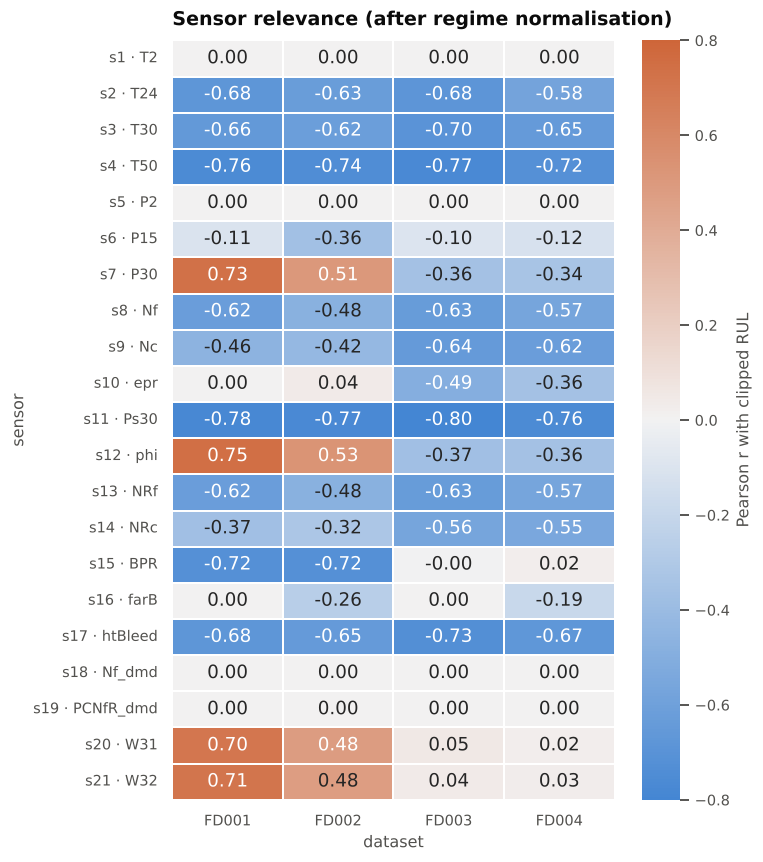

In [6]:
records = []
for name, d in train.items():
    n_cond = cfg["data"]["n_operating_conditions"][name]
    nz = OperatingConditionNormalizer(SENSORS, n_conditions=n_cond, op_cols=ops).fit(d).transform(d)
    for s in SENSORS:
        spread = d[s].std() if n_cond == 1 else nz[s].std()
        corr = np.corrcoef(nz[s], d["rul"])[0, 1] if nz[s].std() > 1e-9 else 0.0
        records.append({"dataset": name, "sensor": s, "corr_with_rul": corr, "std": spread})
sig = pd.DataFrame(records)
pivot = sig.pivot(index="sensor", columns="dataset", values="corr_with_rul").reindex(SENSORS)
fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(pivot, cmap=viz.DIVERGING, center=0, vmin=-0.8, vmax=0.8, annot=True, fmt=".2f",
            linewidths=1, linecolor="white", ax=ax, cbar_kws={"label": "Pearson r with clipped RUL"})
ax.set_yticklabels([f"{s} · {SENSOR_DESCRIPTIONS[s].split(' - ')[0]}" for s in pivot.index], rotation=0)
ax.set_title("Sensor relevance (after regime normalisation)")
fig.tight_layout(); viz.save_figure(fig, "eda_sensor_relevance", FIG); plt.show()

* **s1, s5, s6, s10, s16, s18, s19** carry no degradation information (they are constant or vary only with the regime) → dropped.
* The 14 informative sensors listed in `config.yaml` are consistent across all four datasets, which allows one feature design for every scenario.
* Temperatures (T24, T30, T50), HPC static pressure (Ps30) and fuel-flow ratio (phi) are the strongest individual indicators — consistent with HPC degradation physics: a degraded compressor needs more work (higher temperatures, more fuel) for the same thrust.
* **The fault-mode fingerprint.** P30 (s7), phi (s12), BPR (s15) and the coolant bleeds (s20, s21) are strongly correlated with RUL in the single-fault datasets, but their correlation **collapses or flips sign** in FD003/FD004. A sensor that goes up for one fault mode and down for the other averages out to r ≈ 0 — it is still highly informative, just not *linearly*. These sensors are kept.
* s10 (epr) shows moderate correlation in FD003/FD004; it is a derived pressure ratio largely redundant with P30/Ps30 and is left out to keep one sensor set for every scenario (a candidate for future work).

## 4. Degradation signatures

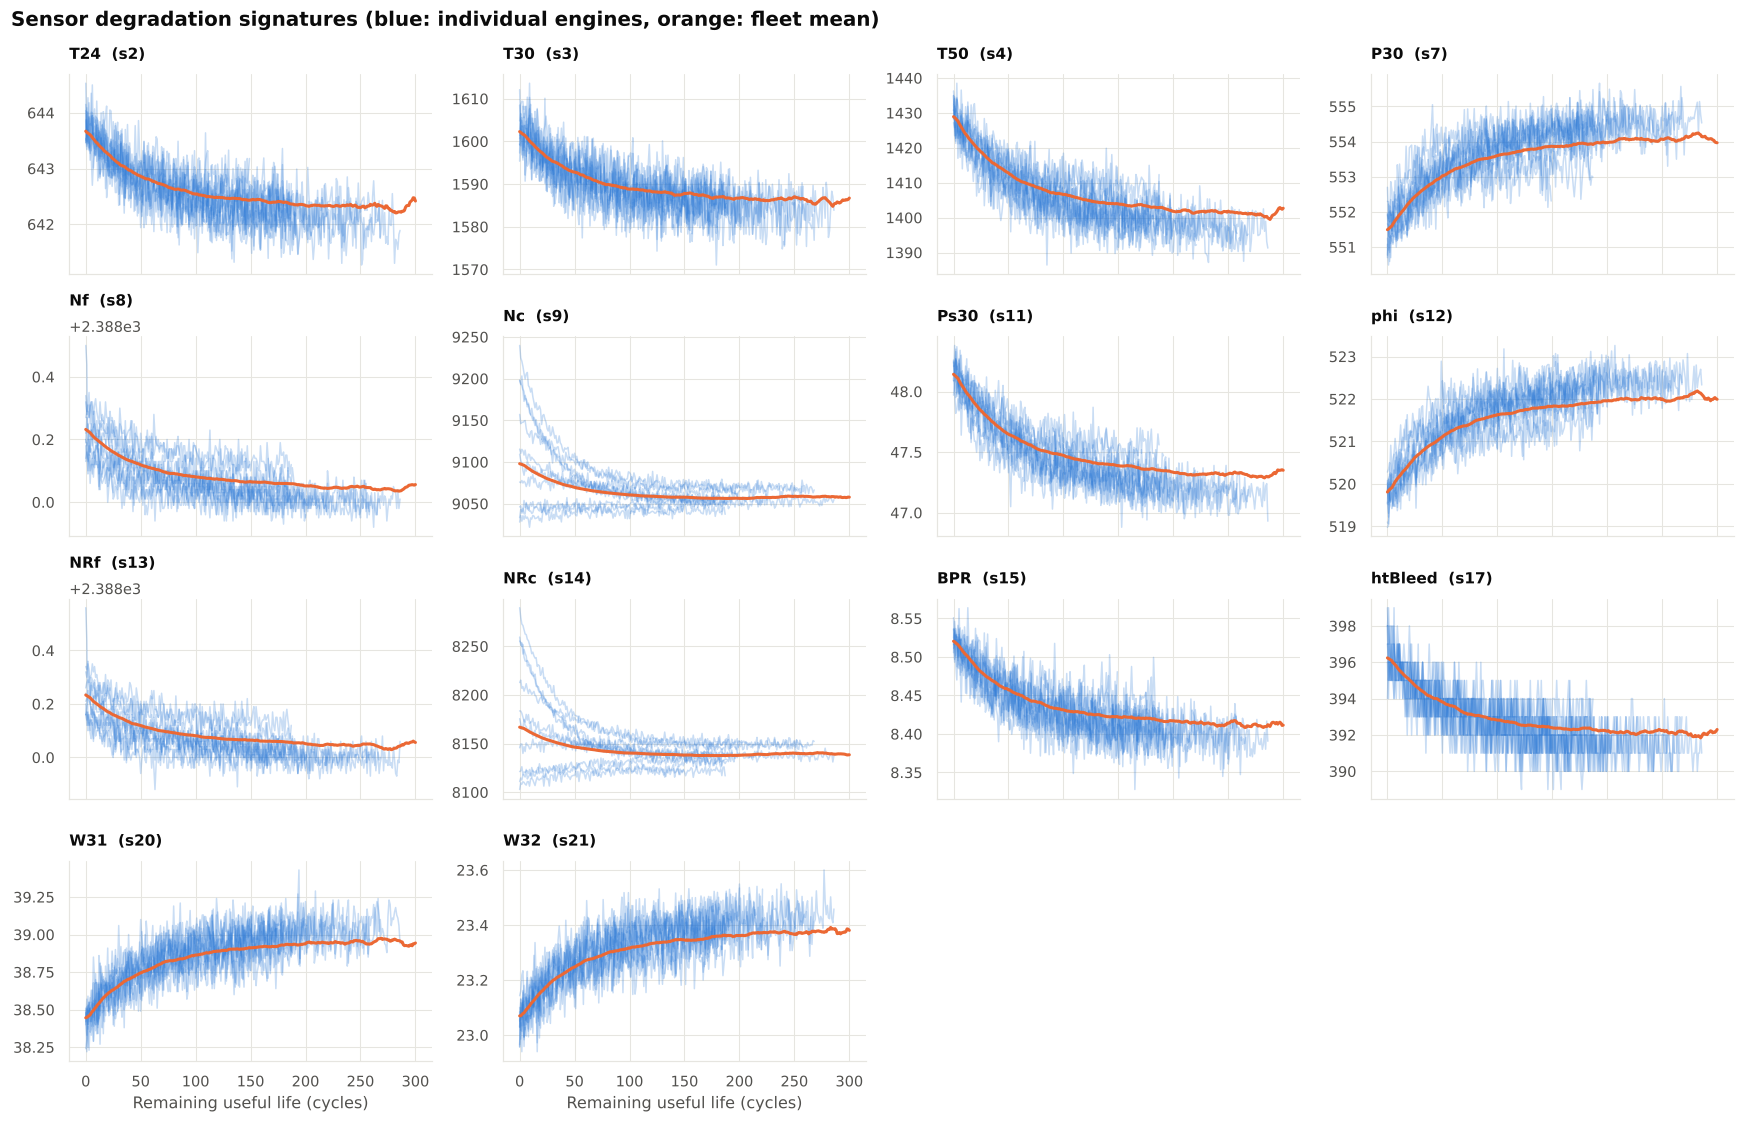

In [7]:
fig = viz.plot_sensor_trends(train["FD001"], cfg["data"]["sensors"], SENSOR_DESCRIPTIONS,
                             units=train["FD001"]["unit"].unique()[:10])
viz.save_figure(fig, "eda_sensor_trends_FD001", FIG); plt.show()

Every informative sensor is **flat for most of the life and then drifts exponentially** in the last ~100 cycles. Two consequences:

1. **RUL clipping**: when RUL > ~125, sensors are indistinguishable from those of a new engine — asking the model to separate RUL = 200 from RUL = 150 is asking it to fit noise. The piece-wise linear target `min(RUL, 125)` (Heimes, 2008) is the industry/literature standard and is what we use.
2. Noise is large relative to the early drift → **smoothing (rolling / EWMA) and trend features (slopes)** will be decisive.

## 5. Two fault modes (FD003)

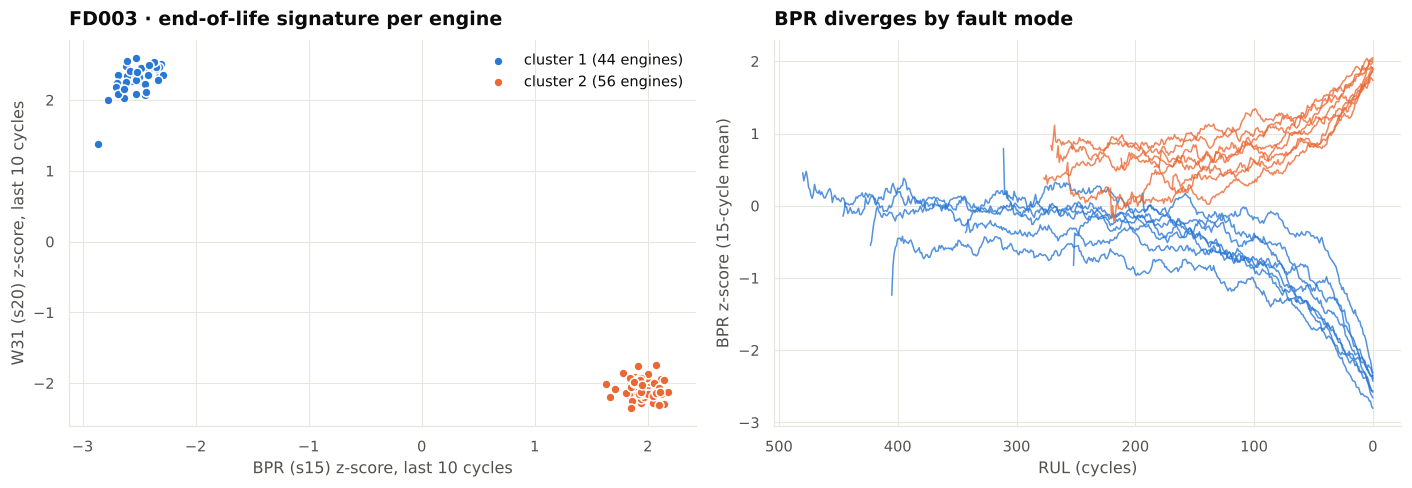

BIC 1 component: 461.6 | BIC 2 components: -45.4


In [8]:
d = train["FD003"]
nz = OperatingConditionNormalizer(cfg["data"]["sensors"], 1, ops).fit(d).transform(d)
from sklearn.mixture import GaussianMixture
end = nz[d["rul_true"] <= 10].groupby(d["unit"]).mean()
gm = GaussianMixture(2, random_state=0).fit(end[["s15", "s20"]])
mode = gm.predict(end[["s15", "s20"]])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for k in range(2):
    axes[0].scatter(end.loc[mode == k, "s15"], end.loc[mode == k, "s20"], color=viz.PALETTE[k], s=34,
                    edgecolor="white", label=f"cluster {k + 1} ({(mode == k).sum()} engines)")
axes[0].set(xlabel="BPR (s15) z-score, last 10 cycles", ylabel="W31 (s20) z-score, last 10 cycles",
            title="FD003 · end-of-life signature per engine"); axes[0].legend()
for k in range(2):
    for unit in end.index[mode == k][:8]:
        m = d["unit"] == unit
        axes[1].plot(d.loc[m, "rul_true"], nz.loc[m, "s15"].rolling(15, min_periods=1).mean(), color=viz.PALETTE[k], lw=1, alpha=0.8)
axes[1].invert_xaxis()
axes[1].set(xlabel="RUL (cycles)", ylabel="BPR z-score (15-cycle mean)", title="BPR diverges by fault mode")
fig.tight_layout(); viz.save_figure(fig, "eda_fault_modes_FD003", FIG); plt.show()
print("BIC 1 component:", round(GaussianMixture(1).fit(end[["s15", "s20"]]).bic(end[["s15", "s20"]]), 1),
      "| BIC 2 components:", round(gm.bic(end[["s15", "s20"]]), 1))

Near failure the FD003 engines split into **two distinct clusters** (a 2-component Gaussian mixture is overwhelmingly preferred by BIC): for one fault mode the bypass ratio rises while the coolant bleed falls, for the other it is the reverse. Temperatures (T50) and HPC pressure (Ps30), in contrast, rise in both modes. A single monotonic health indicator therefore cannot fully describe FD003/FD004 — non-linear tree ensembles, which can learn mode-specific paths, are the appropriate model class.

## 6. Key takeaways for modelling

| Finding | Design decision |
|---|---|
| Regimes explain > 99 % of sensor variance in FD002/FD004 | Per-regime z-scoring (`OperatingConditionNormalizer`) + regime history features |
| 7 sensors are uninformative | Use the 14 informative sensors |
| Degradation is flat, then exponential | RUL clipped at 125; slopes, differences and EWMA features |
| High sensor noise | Multi-window rolling statistics |
| Two fault modes with opposite signatures | Non-linear ensembles (RF, GBM, stacking) |
| Test records are truncated at random | Validation on random truncation points of held-out engines |
| Lifetimes vary 2–3× within a fleet | Strong economic case vs. fixed-interval maintenance |